In [30]:
import pandas as pd

penguins = pd.read_csv("penguins.csv")

penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [31]:
penguins.shape

(344, 8)

In [32]:
penguins.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [33]:
penguins.value_counts()

species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  sex     year
Gentoo   Biscoe  59.6            17.0           230.0              6050.0       male    2007    1
Adelie   Biscoe  34.5            18.1           187.0              2900.0       female  2008    1
                 35.0            17.9           190.0              3450.0       female  2008    1
                                                192.0              3725.0       female  2009    1
                 35.3            18.9           187.0              3800.0       female  2007    1
                                                                                               ..
                 38.1            16.5           198.0              3825.0       female  2009    1
                 37.9            18.6           193.0              2925.0       female  2009    1
                                                172.0              3150.0       female  2007    1
                 37.8            20.0           190.0              4250.0       male    2009    1
                                 18.3           174.0              3400.0       female  2007    1
Name: count, Length: 333, dtype: int64

In [34]:
penguins["species"] .value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Summarize missing data
missing_summary = penguins.isnull().sum()
print("Missing Data Summary:")
print(missing_summary)

Missing Data Summary:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [36]:
# 2. Compare the mean flipper length across species
mean_flipper_length = penguins.groupby('species')['flipper_length_mm'].mean().reset_index()
print("Mean Flipper Length across Species:")
display(mean_flipper_length)

Mean Flipper Length across Species:


,species,flipper_length_mm
0,Adelie,189.953642
1,Chinstrap,195.823529
2,Gentoo,217.186992


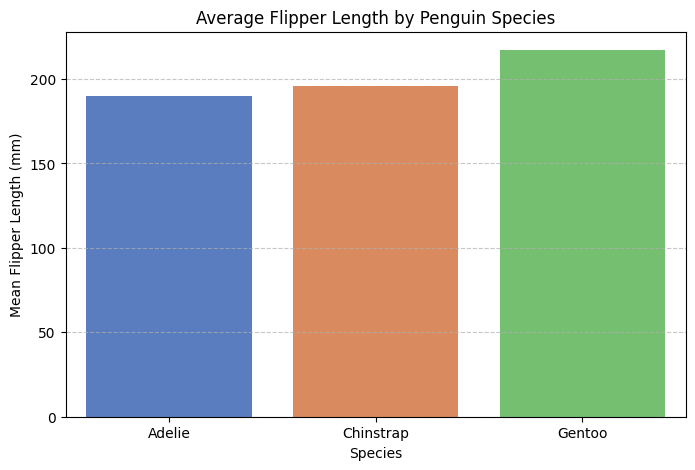

In [37]:
# 3. Produce one labeled bar chart
plt.figure(figsize=(8, 5))
sns.barplot(data=mean_flipper_length, x='species', y='flipper_length_mm', hue='species', legend=False, palette='muted')
plt.title('Average Flipper Length by Penguin Species')
plt.xlabel('Species')
plt.ylabel('Mean Flipper Length (mm)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [38]:
penguins.groupby('species')['flipper_length_mm'].mean()

,flipper_length_mm
species,
Adelie,189.953642
Chinstrap,195.823529
Gentoo,217.186992


I checked the work by running a groupby() and the results matched Gemini's output. I accept that the results are correct for the data.

,Species,Sex,Mean Body Mass (g)
0,Adelie,female,3368.835616
1,Adelie,male,4043.493151
2,Chinstrap,female,3527.205882
3,Chinstrap,male,3938.970588
4,Gentoo,female,4679.741379
5,Gentoo,male,5484.836066


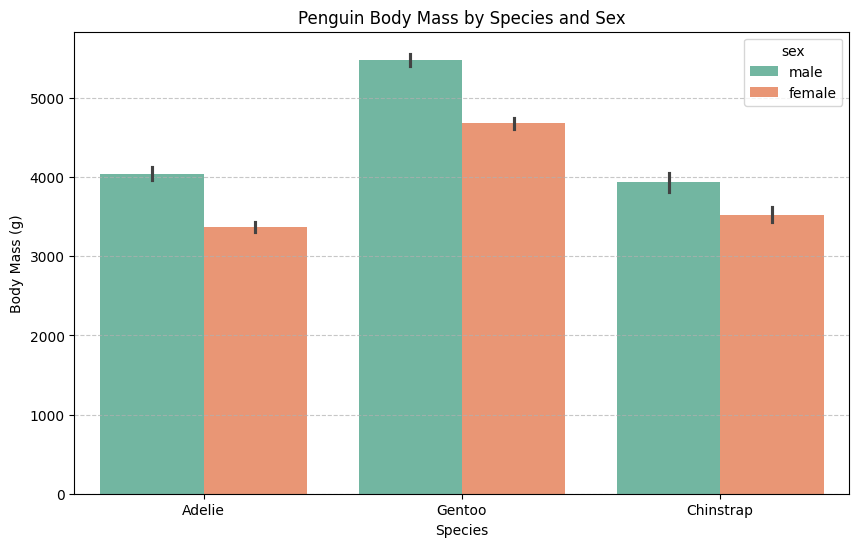

In [39]:
# Calculate mean body mass across species and sex
species_sex_mass = penguins.groupby(['species', 'sex'])['body_mass_g'].mean().reset_index()
species_sex_mass.columns = ['Species', 'Sex', 'Mean Body Mass (g)']
display(species_sex_mass)

# Visualize body mass across species and sex using a grouped bar plot
plt.figure(figsize=(10, 6))
sns.barplot(data=penguins.dropna(subset=['sex']), x='species', y='body_mass_g', hue='sex', palette='Set2')
plt.title('Penguin Body Mass by Species and Sex')
plt.xlabel('Species')
plt.ylabel('Body Mass (g)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

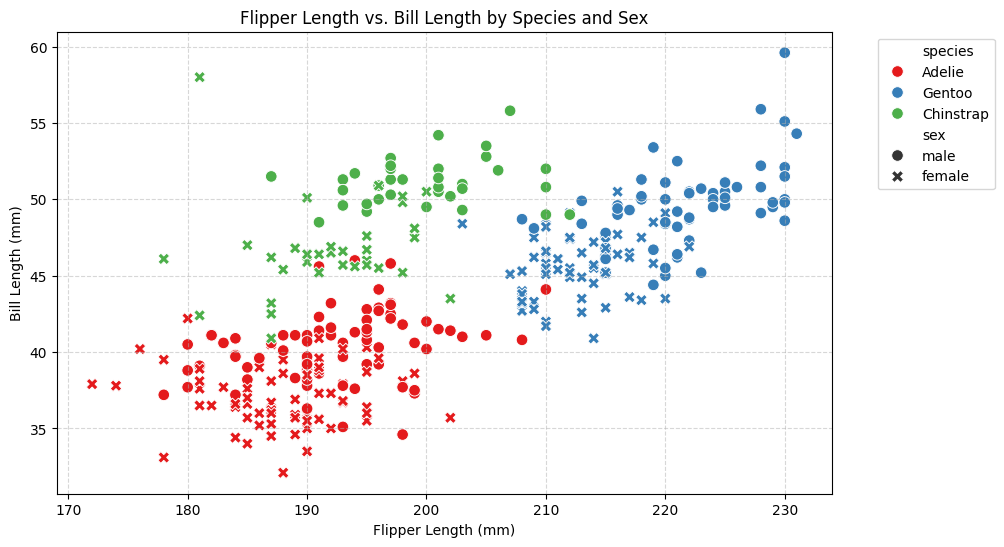

In [40]:
# Relationship between Flipper Length and Bill Length by Species
plt.figure(figsize=(10, 6))
sns.scatterplot(data=penguins.dropna(subset=['flipper_length_mm', 'bill_length_mm']),
                x='flipper_length_mm', y='bill_length_mm', hue='species', style='sex', palette='Set1', s=70)
plt.title('Flipper Length vs. Bill Length by Species and Sex')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Bill Length (mm)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

One insight about penguins the AI did not state is which species appears most often. I ran the chart and it produced Adelie: 152, Gentoo: 124 and Chinstrap: 68.

A dataset from my own work that must never paste into a public AI tool is post client personal information, client addresses, client details. What could do instead is enter an asocciated client number to anonymize the data.

https://github.com/e-flores-data/cs82a-portfolio

Prompt Log: Used Gemini
1 You are helping with exploratory data analysis. My pandas DataFrame is named penguins. It has 344 rows and 8 columns: species, island, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, sex, and year. Write simple Python using pandas and seaborn to: 1. Summarize missing data. 2. Compare the mean flipper length across species. 3. Produce one labeled bar chart.


2  improve the analysis by comparing the body_mass_g across sex. return a small table as the result

3 suggest one follow up analysis that improves the analysis

